# Can a Network Discover $x = x_0 + v\,t$?

**Observation → encoder → latent representation → (+ question) → decoder → answer**

Fig. 4 of *Physics-AI Symbiosis* [1] contrasts two ways of finding a physical law:

* **(a) A human** watches a moving object, notices that two numbers ($x_0$ and $v$) describe it,
  and writes $x(t') = x_0 + v\,t'$.
* **(b) A machine** (SciNet [2]) is an **encoder** $E$ that squeezes the observations into a few latent
  neurons, and a **decoder** $D$ that takes those neurons plus a **question** $q$ and returns an **answer** $a$.

The claim to test is that a small enough bottleneck forces the latent neurons to become the physical
parameters. This notebook trains SciNet on three synthetic systems where we *know* the right
parameters, and measures how far the claim holds:

| system | observation | question | answer | true parameters |
|---|---|---|---|---|
| uniform motion | $x(t_i)$, 10 times | $t'$ | $x(t')$ | $x_0, v$ |
| damped oscillator | $x(t_i)$, 50 times | $t'$ | $x(t')$ | $k, b$ |
| relativistic Doppler | $f(\theta_i)/f_0$, 12 angles | $\theta'$ | $f(\theta')/f_0$ | $\beta$ |

The Doppler case brings in the modern-physics side: at $\theta = 90°$ the shift is pure **time
dilation** (the transverse Doppler effect).

Everything is synthetic, CPU-only, and seeded. Module: [`dgs/scinet_discovery.py`](../dgs/scinet_discovery.py)

**References (IEEE)**
1. B. Jalali, A. Kadambi, and V. Roychowdhury, "Physics-AI symbiosis," arXiv:2109.05959, 2021.
2. R. Iten, T. Metger, H. Wilming, L. del Rio, and R. Renner, "Discovering physical concepts with neural networks," *Phys. Rev. Lett.*, vol. 124, no. 1, Art. no. 010508, 2020.
3. D. P. Kingma and M. Welling, "Auto-encoding variational Bayes," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2014.
4. I. Higgins *et al.*, "β-VAE: Learning basic visual concepts with a constrained variational framework," in *Proc. ICLR*, 2017.
5. H. E. Ives and G. R. Stilwell, "An experimental study of the rate of a moving atomic clock," *J. Opt. Soc. Am.*, vol. 28, no. 7, pp. 215–226, 1938.

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Math
sp.init_printing()          # renders SymPy results as LaTeX in the notebook
from dgs import scinet_discovery as S
print("torch", torch.__version__, "| running on CPU")

torch 2.11.0+cu128 | running on CPU


# 1. The physics the network should find (SymPy)

`sp.init_printing()` makes every SymPy result below display as typeset math instead of plain text.
It changes only the display, not the math.

**Relativistic Doppler.** A source moving at $\beta = v/c$ along $x$ emits frequency $f_0$ in its
own frame. The photon's four-wavevector $(\omega/c,\,\mathbf k)$ transforms like $(ct,\,\mathbf x)$, so
$\omega_{\text{source}} = \gamma(\omega - v k_x) = \gamma\omega(1-\beta\cos\theta)$, where $\theta$ is the
lab-frame angle between the motion and the line of sight. Solving for the lab frequency:

In [2]:
ratio, transverse = S.doppler_symbolic()
display(Math(r"\frac{f}{f_0} = " + sp.latex(ratio) + r",\qquad \left.\frac{f}{f_0}\right|_{\theta=90^\circ} = " + sp.latex(transverse) + r" = \frac{1}{\gamma}"))
beta, theta = sp.symbols("beta theta", real=True)
display(Math(r"\text{first order in } \beta:\; " + sp.latex(sp.series(ratio, beta, 0, 2).removeO())))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

To first order this is the classical $1+\beta\cos\theta$, which vanishes at $90°$. The transverse shift
$\sqrt{1-\beta^2}$ is second order in $\beta$ and has **no** classical counterpart: it is the moving
clock running slow. Ives and Stilwell measured it in 1938 [5].

**Damped oscillator.** $x'' + b x' + k x = 0$ with $x(0)=1$, $x'(0)=0$. Writing $k=\omega^2+b^2/4$:

In [3]:
sol, check = S.damped_oscillator_symbolic()
display(sol)
print("difference from the formula used to generate the data:", check)

difference from the formula used to generate the data: 0


# 2. The network

```
observation o (10–50 numbers) ─► encoder E: 100 → 100 → (mu, log var) for 3 latent neurons
                                                    │  sample z = mu + sigma·noise
question q (1 number) ──────────────────────────────┤
                                                    ▼
                                decoder D: (z, q) → 100 → 100 → answer a
```

**Loss** = mean squared error of the answer + $\beta_{KL}\times$ KL divergence of each latent
neuron's distribution from a standard normal.

The KL term is the "keep it simple" pressure ($\beta$-VAE [3], [4]). A neuron the decoder doesn't need
is cheapest when it carries no information ($\mu=0$, $\sigma=1$, KL $=0$). So **active neurons**
(KL clearly above zero) estimate how many numbers the system needs. Note that $\beta_{KL}$ is the
penalty weight, unrelated to the relativistic $\beta$.

Three latent neurons are offered every time. The network has to decide how many to use.

# 3. Uniform motion: the example in the paper's figure

In [4]:
t0 = time.time()
m_u, d_u, h_u = S.train("uniform motion", beta_kl=1e-3, steps=4000)
test_u = S.make_data("uniform motion", n=4000, seed=99)
r_u = S.latent_report(m_u, test_u)
print(f"trained in {time.time()-t0:.0f} s;  test answer MSE = {r_u['mse']:.2e}")
display(pd.DataFrame({"KL": r_u["kl"].round(3), "|r| with x0": r_u["corr"][:, 0].round(3),
                      "|r| with v": r_u["corr"][:, 1].round(3)}, index=[f"z{i}" for i in range(3)]))
print("active neurons:", [int(i) for i in r_u["active"]], "  R^2 of (x0, v) from active neurons:", r_u["r2"].round(4))

trained in 12 s;  test answer MSE = 4.99e-05


,KL,|r| with x0,|r| with v
z0,0.004,0.121,0.394
z1,3.624,0.667,0.738
z2,2.304,0.659,0.758


active neurons: [1, 2]   R^2 of (x0, v) from active neurons: [1.     0.9998]


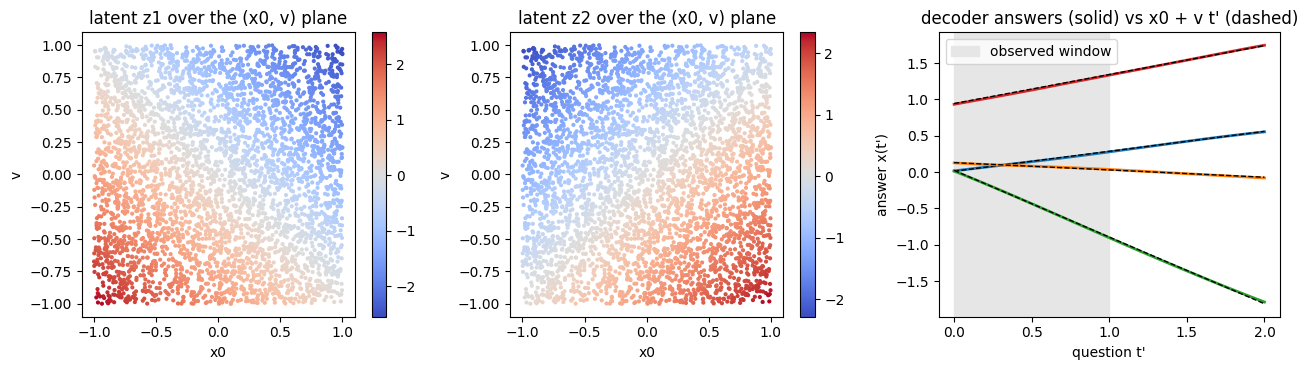

In [5]:
z = r_u["z"]; p = test_u["params"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for k, i in enumerate(r_u["active"][:2]):
    sc = ax[k].scatter(p[:, 0], p[:, 1], c=z[:, i], s=4, cmap="coolwarm")
    ax[k].set_xlabel("x0"); ax[k].set_ylabel("v"); ax[k].set_title(f"latent z{i} over the (x0, v) plane")
    plt.colorbar(sc, ax=ax[k])
q = np.linspace(0, 2, 50).astype(np.float32)
for j in range(4):
    o = torch.tensor(np.repeat(test_u["obs"][j:j+1], 50, 0)); qq = torch.tensor(q[:, None])
    with torch.no_grad(): a = m_u(o, qq, sample=False)[0].numpy()[:, 0]
    ax[2].plot(q, a, lw=2); ax[2].plot(q, p[j, 0] + p[j, 1]*q, "k--", lw=1)
ax[2].axvspan(0, 1, color="0.9", label="observed window"); ax[2].set_xlabel("question t'"); ax[2].set_ylabel("answer x(t')")
ax[2].set_title("decoder answers (solid) vs x0 + v t' (dashed)"); ax[2].legend()
plt.tight_layout(); plt.show()

**What was found, and what wasn't:**

* **Found.** Exactly two neurons are active, and together they determine $x_0$ and $v$
  ($R^2 \approx 1$). The decoder also extrapolates correctly past the observed window, out to $t'=2$.
  That is the "two numbers describe it" step of Fig. 4(a).
* **Not found.** No single neuron *is* $x_0$ or *is* $v$. The color maps are tilted stripes, so each
  neuron is a mixture of the two. Any rotation of $(x_0, v)$ answers the questions equally well, and
  the loss has no reason to prefer the human axes.
* **Not found.** The network never writes $x_0 + v t'$. The formula is spread across 10,000 decoder
  weights. Getting a symbolic law out still needs a person, or a symbolic-regression step on the
  decoder.

So the bottleneck finds **how many** parameters there are, and a coordinate system for them. It does
not find their names or the equation.

# 4. Relativistic Doppler: one parameter, and time dilation from a network

answer MSE = 2.59e-04;  KL per neuron = [0.01  2.343 0.009];  active = [1];  R^2(beta) = 0.99988


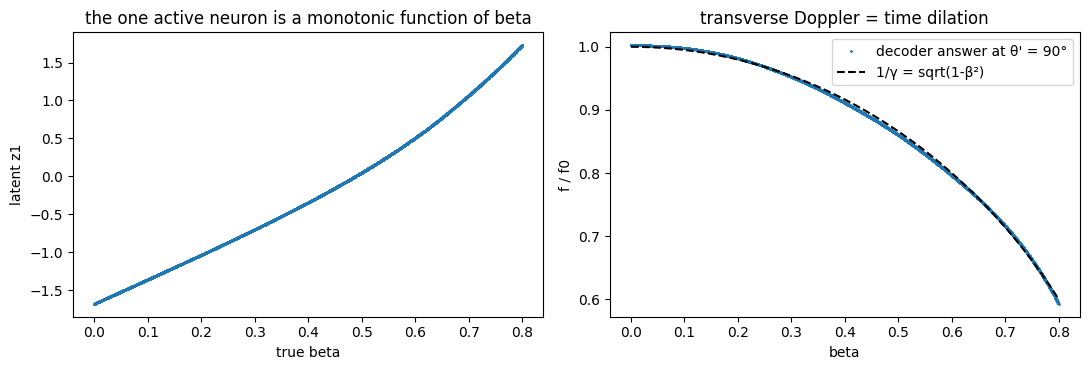

max |decoder - 1/gamma| at 90 deg: 0.0073


In [6]:
m_d, d_d, _ = S.train("relativistic Doppler", beta_kl=1e-3, steps=4000)
test_d = S.make_data("relativistic Doppler", n=4000, seed=99)
r_d = S.latent_report(m_d, test_d)
print(f"answer MSE = {r_d['mse']:.2e};  KL per neuron = {r_d['kl'].round(3)};  active = {[int(i) for i in r_d['active']]};  R^2(beta) = {r_d['r2'][0]:.5f}")
i = r_d["active"][0]
b = test_d["params"][:, 0]
with torch.no_grad():
    f90 = m_d(torch.tensor(test_d["obs"]), torch.full((len(b), 1), np.pi/2), sample=False)[0].numpy()[:, 0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(b, r_d["z"][:, i], ".", ms=2); ax[0].set_xlabel("true beta"); ax[0].set_ylabel(f"latent z{i}")
ax[0].set_title("the one active neuron is a monotonic function of beta")
o = np.argsort(b)
ax[1].plot(b[o], f90[o], ".", ms=2, label="decoder answer at θ' = 90°")
ax[1].plot(b[o], np.sqrt(1 - b[o]**2), "k--", label="1/γ = sqrt(1-β²)")
ax[1].set_xlabel("beta"); ax[1].set_ylabel("f / f0"); ax[1].legend(); ax[1].set_title("transverse Doppler = time dilation")
plt.tight_layout(); plt.show()
print("max |decoder - 1/gamma| at 90 deg:", np.max(np.abs(f90 - np.sqrt(1 - b**2))).round(4))

One neuron is active, and it tracks $\beta$ monotonically, so it is $\beta$ up to a relabeling.
With a single parameter there is no rotation ambiguity, which is why this case comes out cleanest.
The decoder's answer at $90°$ follows $1/\gamma$. **But** 90° is just one of the questions it was
trained on. The network reproduces time dilation, it did not *discover* the concept: we chose to
observe frequencies at angles, and that choice already contains the physics.

# 5. Damped oscillator: the answer depends on the simplicity pressure

Here the two parameters matter very unequally. $k$ sets the oscillation frequency, which changes
every sample. $b \in [0.5, 1]$ only changes the decay envelope slightly. We sweep $\beta_{KL}$ and
record, for each latent neuron:

* its KL;
* how much the answer error grows when that neuron is frozen at its mean (ablation);
* how well the active neurons predict $k$ and $b$.

In [7]:
test_o = S.make_data("damped oscillator", n=4000, seed=99)
rows, models = [], {}
for bk in (1e-3, 5e-4, 1e-4):
    t0 = time.time()
    m, _, _ = S.train("damped oscillator", beta_kl=bk, steps=6000)
    r = S.latent_report(m, test_o); base, abl = S.ablation(m, test_o); models[bk] = (m, r)
    rows.append({"beta_KL": bk, "KL per neuron": np.round(r["kl"], 2), "active (KL>0.05)": len(r["active"]),
                 "ablation base": round(base, 3), "ablation rel. MSE per neuron": np.round(abl, 3),
                 "R2 k": round(r["r2"][0], 4), "R2 b": round(r["r2"][1], 4),
                 "answer MSE": f"{r['mse']:.1e}", "s": round(time.time() - t0)})
pd.DataFrame(rows)

,beta_KL,KL per neuron,active (KL>0.05),ablation base,ablation rel. MSE per neuron,R2 k,R2 b,answer MSE,s
0,0.0010,"[1.59, 0.05, 0.01]",1,0.066,"[0.206, 0.067, 0.066]",0.9977,0.0031,5.0e-03,21
1,0.0005,"[3.72, 0.12, 0.8]",3,0.040,"[0.183, 0.041, 0.057]",0.9999,0.9971,3.0e-03,20
2,0.0001,"[6.33, 3.89, 1.53]",3,0.040,"[0.06, 0.139, 0.054]",0.9999,0.9982,3.0e-03,21


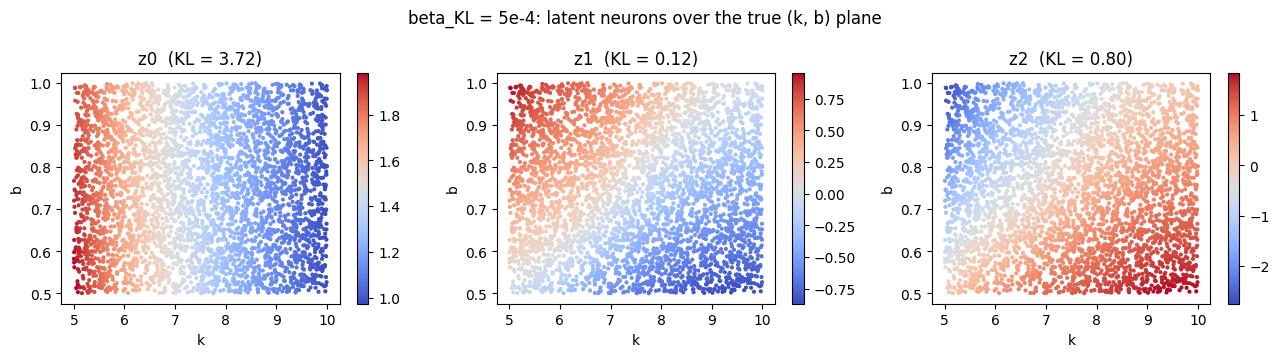

In [8]:
m, r = models[5e-4]
ks, bs = test_o["params"][:, 0], test_o["params"][:, 1]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for j in range(3):
    sc = ax[j].scatter(ks, bs, c=r["z"][:, j], s=4, cmap="coolwarm"); plt.colorbar(sc, ax=ax[j])
    ax[j].set_xlabel("k"); ax[j].set_ylabel("b"); ax[j].set_title(f"z{j}  (KL = {r['kl'][j]:.2f})")
plt.suptitle("beta_KL = 5e-4: latent neurons over the true (k, b) plane"); plt.tight_layout(); plt.show()

Read the sweep honestly:

* **Strong pressure ($10^{-3}$).** Only one neuron survives, and it is $k$. The network decides that
  $b$'s small effect on the envelope isn't worth the KL cost, so $R^2(b)\approx0$. It *undercounts*
  the parameters.
* **Weaker pressure.** $b$ comes back ($R^2 \approx 0.997$), but then the third neuron doesn't fully
  switch off. With an absolute KL threshold the network *overcounts* (3 "active" neurons for a
  2-parameter system). One neuron is clean $k$ (vertical stripes); $b$ is spread across the others.
* Iten et al. report two clean neurons for this system [2], after tuning. The number of parameters
  SciNet reports is therefore partly a choice made by whoever sets $\beta_{KL}$ and the activity threshold.

This is the paper's interpretability point in miniature. A latent representation is compact, but
reading physics out of it takes ground truth (here, the known $k$ and $b$) or careful ablation. That is
exactly the information you don't have when the physics is genuinely unknown.

# 6. Where this fits: physics-AI design choices

| choice | human route (Fig. 4a) | SciNet route (Fig. 4b) |
|---|---|---|
| what to observe | chosen by physicist | chosen by physicist (same!) |
| how many parameters | insight | KL bottleneck, depends on $\beta_{KL}$ |
| which coordinates | named physical quantities | any invertible mix |
| the law | symbolic, extrapolates | inside decoder weights; extrapolates only where trained |
| compute | pencil | about 20 s of CPU per system here |

For hardware design, the useful part is the **compact representation**. A small latent vector is a
cheap thing to transmit or store from a sensor (low bandwidth, low power), as long as the decoder lives
on the receiving end.

# Appendix A: Nilsson P5.5 (ideal op amp, current-source input)

The + input is grounded, so the ideal op amp forces $v_n = 0$ and draws no input current. All 0.5 mA
of the source goes through the 10 kΩ feedback resistor, from the inverting node to the output:
$$0 - v_o = (0.5\ \text{mA})(10\ \text{k}\Omega) \;\Rightarrow\; v_o = -5\ \text{V} \quad(\text{inside the } \pm6\ \text{V rails}).$$

In [9]:
vo = sp.symbols("v_o")
v_o = sp.solve(sp.Eq(sp.Rational(1, 2000), (0 - vo) / 10_000), vo)[0]
i_5k, i_25k = v_o / 5000, v_o / 2500
i_feedback_into_out = (0 - v_o) / 10_000
i_opamp_out = i_25k + i_5k - i_feedback_into_out     # KCL at the output node
print(f"v_o = {v_o} V")
print(f"current in 5 kΩ = {i_5k*1e3} mA,  in 2.5 kΩ = {i_25k*1e3} mA")
print(f"op-amp output terminal current = {i_opamp_out*1e3} mA (negative: the op amp sinks 3.5 mA)")

v_o = -5 V
current in 5 kΩ = -1.00000000000000 mA,  in 2.5 kΩ = -2.00000000000000 mA
op-amp output terminal current = -3.50000000000000 mA (negative: the op amp sinks 3.5 mA)


In the figure the $i_o$ arrow is drawn on the wire **after** the junction where the 10 kΩ and 2.5 kΩ
connect, so it is the current into the 5 kΩ: $\boxed{i_o = -5/5000 = -1\ \text{mA}}$ (1 mA flowing up,
toward the output node). If your copy draws $i_o$ right at the op-amp terminal, it is the KCL total,
$-3.5$ mA.

# Appendix B: exp and log amplifiers

Put a diode (or a BJT) in the op-amp's feedback path and its exponential I–V law becomes the
transfer function. With the diode law $i = I_S e^{v/V_T}$ and the virtual ground at $v_n = 0$:

* **Log amp** (diode in feedback, $R$ at the input): $v_{in}/R = I_S e^{-v_o/V_T}$.
* **Antilog (exp) amp** (diode at the input, $R$ in feedback): $v_o = -R I_S e^{v_{in}/V_T}$.

In [10]:
vin, vo, R, Is, VT = sp.symbols("v_in v_o R I_S V_T", positive=True)
log_amp = sp.solve(sp.Eq(vin / R, Is * sp.exp(-vo / VT)), vo)[0]
display(Math(r"\text{log amp: } v_o = " + sp.latex(sp.simplify(log_amp))))
display(Math(r"\text{exp amp: } v_o = " + sp.latex(-R * Is * sp.exp(vin / VT))))
num = {R: 10e3, Is: 1e-14, VT: 0.02585}
f = sp.lambdify(vin, log_amp.subs(num))
print("log amp, one decade of input -> output step:", f"{f(1.0) - f(0.1):.4f} V  (= -V_T ln 10 = {-0.02585*np.log(10):.4f} V)")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

log amp, one decade of input -> output step: -0.0595 V  (= -V_T ln 10 = -0.0595 V)


Every decade of input moves the output by $-V_T\ln 10 \approx -60$ mV at room temperature. A log amp
compresses a dynamic range of several decades (photodiode currents, RF power detectors) into a few
hundred millivolts. Note that $V_T = kT/q$, so real log amps need temperature compensation: the same
diode physics that gives the log also gives the drift.

## Exercises
1. Train uniform motion with only 1 latent neuron offered. What happens to the answer MSE, and why does that prove two parameters are needed?
2. Fit a linear map from the two active neurons in §3 to $(x_0, v)$. Is it a rotation, a shear, or something nonlinear?
3. Add noise (`noise=0.02`) to the Doppler observations. How does $R^2(\beta)$ degrade?
4. Ask the Doppler decoder about $\theta' = 0$ and compare with $\sqrt{(1+\beta)/(1-\beta)}$, the longitudinal shift.
5. For the log amp, how many decades of photodiode current (1 nA to ?) fit within a ±5 V output swing?